# Jak wygląda hejt? Charakterystyka hejtu ogólnego (HerBERT)

Pozostałe notebooki sprawdzają, **czy wydarzenia zmieniają poziom hejtu**. Ten notebook opisuje, **czym hejt różni się od zwykłych komentarzy**:
jakie ma cechy językowe, jak jest długi, czy dostaje więcej polubień i odpowiedzi oraz czy hejt piszą osoby, które piszą wyłącznie hejt.

**Dane** (te same co w `6_wyniki_koncowe/cross_platform_hate_analysis_herbert.ipynb`):

- 11 wydarzeń × 3 platformy, okno −7…+14 dni, bez komórki YouTube / Smierc_Zolnierza,
- tylko komentarze w **filtrze tematycznym** (słowo o migracji albo obelga w komentarzu lub we wpisie) – tylko one mają etykietę HerBERT-a,
- etykieta `hate` = `hate_final` z `herbert/comments.csv`: obelga ze słownika → 1, w pozostałych HerBERT (p ≥ 0,5).

**Słownik obelg.** Komentarze z obelgą ze słownika mają `hate = 1` z definicji. W regresji (sekcja 4) pomijamy je, żeby wynik
pokazywał, co rozpoznaje sam model, a nie odtwarzał słownik. Opisowo (sekcje 1–3) pokazujemy wszystkie komentarze.

**Wykresy** są po polsku. Te same wykresy po angielsku (do preprintu) zapisują się w `reports/hate_analysis/en/`.

| Sekcja | Pytanie |
|---|---|
| 1 | Ile jest hejtu na platformach i wydarzeniach? |
| 2 | Jak często hejt ma daną cechę (wulgaryzmy, wykrzykniki, CAPS, zwrot „ty/wy”, wzmianki o grupach…) w porównaniu ze zwykłymi komentarzami? |
| 3 | Czy hejt jest dłuższy czy krótszy? |
| 4 | Które cechy są związane z hejtem, gdy uwzględnimy wszystkie naraz (regresja logistyczna)? |
| 5 | Czy hejt dostaje więcej polubień i odpowiedzi? |
| 6 | Czy hejterzy piszą wyłącznie hejt? |
| 7 | Podsumowanie i wnioski |

In [1]:
import gc
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
EVENTS = json.loads((ROOT / "events.json").read_text(encoding="utf-8"))

PLATFORMS = ["wykop", "youtube", "bluesky"]
EVENT_TYPE = {
    "Pakt_Azyl_PE": "polityczne", "Atak_Zolnierz_Granica": "kryminalne", "Smierc_Zolnierza": "kryminalne",
    "Bojka_Srem": "kryminalne", "Strategia_Migracyjna": "polityczne", "Naloty_ICE_Los_Angeles": "polityczne",
    "Dezinformacja_Krakow": "dezinformacja", "Pakt_Migracyjny_Wejscie_w_Zycie": "polityczne",
    "Ceuta_Masowe_Przekroczenie": "kryzys graniczny", "Atak_Kamienna_Gora": "kryminalne", "Atak_Jaroslaw": "kryminalne",
}
EXCLUDE = {("youtube", "Smierc_Zolnierza")}
WINDOW = (-7, 14)

OUT = ROOT / "reports" / "hate_analysis"
OUT_EN = OUT / "en"
OUT_EN.mkdir(parents=True, exist_ok=True)
COL = {"wykop": "#2a78d6", "youtube": "#eb6834", "bluesky": "#1baf7a"}
HATE_C, NON_C, INK = "#b4381f", "#9aa3ad", "#222222"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 220, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlesize": 11, "axes.titleweight": "bold", "font.size": 9})


def save(fig, name, lang="pl"):
    fig.savefig((OUT if lang == "pl" else OUT_EN) / f"{name}.png", bbox_inches="tight", facecolor="white")


# Napisy na wykresach: (polski, angielski)
TXT = {
    "hate": ("hejt", "hate"), "non": ("bez hejtu", "non-hate"),
    "Język": ("Język", "Language"), "Forma": ("Forma", "Form"), "Adresat": ("Adresat", "Addressee"),
    "Grupy": ("Wzmianki o grupach", "Groups mentioned"),
}

## 0. Wczytanie danych

Łączymy `clean/comments.csv` (tekst, wątek, polubienia, odpowiedzi, autor) z `herbert/comments.csv` (etykieta) po `comment_id`.

In [2]:
CLEAN_COLS = ["comment_id", "relative_day", "thread_id", "author_id", "likes", "replies", "text", "text_raw"]
HERB_COLS = ["comment_id", "hate_final", "label_source"]


def load_cell(platform, event):
    folder = ROOT / "data" / "interim" / platform / f"{EVENTS[event]}_{event}"
    cf, hf = folder / "clean" / "comments.csv", folder / "herbert" / "comments.csv"
    if not (cf.exists() and hf.exists()):
        return None
    c = pd.read_csv(cf, encoding="utf-8-sig", usecols=lambda x: x in CLEAN_COLS,
                    dtype={"comment_id": str, "thread_id": str, "author_id": str}).drop_duplicates("comment_id")
    h = pd.read_csv(hf, encoding="utf-8-sig", usecols=HERB_COLS, dtype={"comment_id": str}).drop_duplicates("comment_id")
    d = c[c["relative_day"].between(*WINDOW)].merge(h, on="comment_id", how="inner")
    d["platform"], d["event"], d["type"] = platform, event, EVENT_TYPE[event]
    d["cell"] = platform + ":" + event
    d["thread"] = d["cell"] + ":" + d["thread_id"].astype(str)
    # Wykop: id autora globalne; Bluesky: pseudonimy nadawane osobno w każdym wydarzeniu
    d["author"] = d["author_id"] if platform == "wykop" else event + ":" + d["author_id"].astype(str)
    d.loc[d["author_id"].isna(), "author"] = np.nan
    return d.drop(columns=["thread_id", "author_id"])


frames = [load_cell(p, e) for p in PLATFORMS for e in EVENT_TYPE if (p, e) not in EXCLUDE]
df = pd.concat([f for f in frames if f is not None], ignore_index=True)
del frames
df["hate"] = df["hate_final"].astype(int)
df["text"] = df["text"].fillna("").astype(str)
df["text_raw"] = df["text_raw"].fillna(df["text"]).astype(str)
for c in ("likes", "replies"):
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["dict"] = df["label_source"].eq("slownik")
PL = [p for p in PLATFORMS if p in set(df["platform"])]
print(f"{len(df):,} komentarzy w filtrze tematycznym, {df['cell'].nunique()} komórek, {df['event'].nunique()} wydarzeń")

250,596 komentarzy w filtrze tematycznym, 32 komórek, 11 wydarzeń


## 1. Ile jest hejtu?

Poziomy porównujemy tylko w obrębie platformy: platformy różnią się sposobem zbierania danych (YouTube – wszystkie komentarze z wybranych kanałów,
Wykop i Bluesky – wpisy znalezione po słowach kluczowych).

,komentarze,hejt,ze_slownika,hejt %,% hejtu ze słownika
platform,,,,,
wykop,86421,29151,2336,33.7,8.0
youtube,145471,63298,8610,43.5,13.6
bluesky,18704,3736,98,20.0,2.6


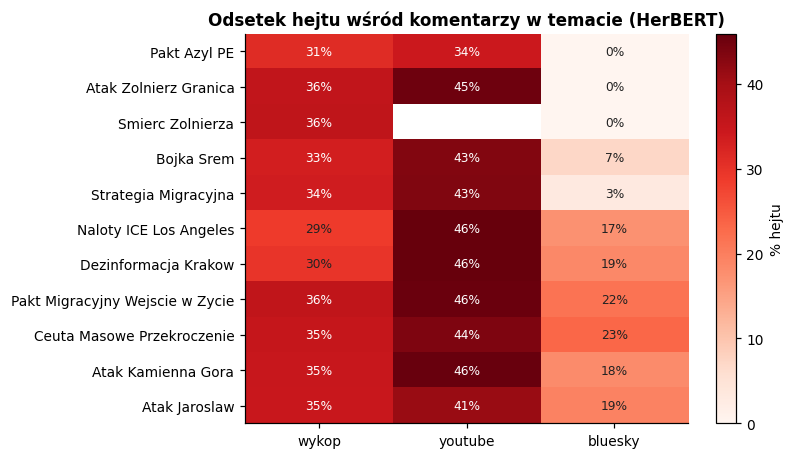

In [3]:
lvl = (df.groupby("platform").agg(komentarze=("hate", "size"), hejt=("hate", "sum"), ze_slownika=("dict", "sum")).reindex(PL))
lvl["hejt %"] = 100 * lvl["hejt"] / lvl["komentarze"]
lvl["% hejtu ze słownika"] = 100 * lvl["ze_slownika"] / lvl["hejt"]
display(lvl.round(1))

ev = df.pivot_table(index="event", columns="platform", values="hate", aggfunc="mean").reindex(index=list(EVENT_TYPE), columns=PL) * 100
fig, ax = plt.subplots(figsize=(6.5, 4.6))
im = ax.imshow(ev.values, cmap="Reds", vmin=0, vmax=np.nanmax(ev.values), aspect="auto")
ax.set_xticks(range(len(PL)), PL)
ax.set_yticks(range(len(ev)), [e.replace("_", " ") for e in ev.index])
for i in range(ev.shape[0]):
    for j in range(ev.shape[1]):
        v = ev.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=8, color="white" if v > 30 else INK)
ax.set_title("Odsetek hejtu wśród komentarzy w temacie (HerBERT)")
fig.colorbar(im, ax=ax, label="% hejtu")
save(fig, "ha_1_poziomy")
plt.show()

## 2. Cechy hejtu

Każda cecha to prosta reguła: komentarz ma cechę, jeśli zawiera któreś słowo z listy (liczymy od początku słowa, więc „debil” łapie też „debilu”, „debile”)
albo dany znak. Wielkie litery i emoji sprawdzamy w tekście przed czyszczeniem (`text_raw`), resztę w tekście po czyszczeniu.

| Cecha | Kiedy komentarz ją ma |
|---|---|
| **wulgaryzmy** | rdzenie: kurw-, chuj-, huj-, pierdol-, pierdal-, jeba-, jebi-, jebn-, zajeb-, wyjeb-, pojeb-, pizd-, skurw-, spierd-, wypierd-, zjeb-, dziwk- |
| **wyzwiska** | debil-, idiot-, kretyn-, głup-, durni-, dureń, matoł-, baran-, osioł, kmiot-, tępak-, tępy, upośledz-, imbecyl-, cymbał-, frajer-, szmat-, gnoj-, gówn- |
| **słowa odczłowieczające** | robactwo, robak-, szczur-, pasożyt-, zwierzę-, bydł-, ścierw-, gnid-, małp-, szkodnik-, hołot-, dzicz-, dzikus-, bestia, potwor-, śmieci |
| **wezwanie do wykluczenia** | wypierdal-, won, precz, wracaj-, „wracać do”, deport-, wyrzucić, wywalić, odesłać, wydalić, „zamknąć granic-” |
| **przemoc** | zabić, zabij-, rozstrzel-, powiesić, wieszać, spalić, zastrzel-, odstrzel-, utopić, eksterminac-, wystrzelać |
| **wykrzyknik** | co najmniej jeden „!” |
| **pytanie** | co najmniej jeden „?” |
| **CAPS LOCK** | co najmniej 8 liter i co najmniej połowa z nich wielkimi literami |
| **emoji** | co najmniej jedno emoji (na Wykopie emoji i CAPS prawie nie występują w pobranym tekście – poniżej 1% komentarzy) |
| **krótki / długi** | ≤ 10 słów / > 50 słów |
| **zwrot do rozmówcy (ty/wy)** | całe słowa: ty, cię, ciebie, tobie, twój…, wy, was, wam, wasz…, jesteś, jesteście |
| **„my / nas”** | całe słowa: my, nas, nam, nasz, nasza, nasze… |
| **„oni / tacy”** | całe słowa: oni, one, nimi, tacy, takich, „tych ludzi”, „ci ludzie” |
| **Ukraińcy** | ukrai-, ukraiń-, ukrop-, bander-, chachoł-, ukry, ukrów, upadlin- |
| **migranci (ogólnie)** | migran-, imigran-, emigran-, uchodź-, nachodź-, najeźdź-, przybysz-, nielegal-, azyl- |
| **muzułmanie / Arabowie / Afrykanie** | muzułm-, islam-, arab-, allah, ciap-, murzyn-, afryk-, czarnuch-, czarnoskór-, syryj-, afgan-, talib-, szariat-, meczet-, turk-/turc- |
| **Rosjanie** | rosj-, rosyj-, rusk-, kacap-, putin-, moskal-, onuc- |
| **Polacy / Polska** | polak-, polac-, polsk-, polek- |
| **politycy / partie** | pis (całe słowo), pisow-, tusk-, kaczyń-, konfeder-, bosak-, mentzen-, „platforma obywatel-”, lewic-, rząd, sejm-, polityk-, prezydent-, dud-, nawrock-, trzaskowsk-, minist-, ue, unia/unii, bruksel- |
| **etykiety ideologiczne** | lewak-, lewact-, prawak-, katol-, faszyst-, nazist-, komuch-, tęczow-, lgbt, neomark-, pisior-, peowiec-, platfus-, kaczyst-, konfiarz- |

**Jak czytać wykres:** dla każdej cechy czerwona kropka to odsetek komentarzy **z hejtem**, które mają tę cechę, a szara – odsetek komentarzy **bez hejtu**.
Im dalej kropki od siebie, tym bardziej cecha odróżnia hejt. Kolumna `ile razy częściej` w tabeli = odsetek w hejcie ÷ odsetek bez hejtu.

In [4]:
def rx(stems):
    """Rdzenie dopasowujemy od początku słowa; rdzeń zakończony '$' musi być całym słowem."""
    body = "|".join(s[:-1] + r"(?!\w)" if s.endswith("$") else s for s in stems)
    return re.compile(rf"(?<!\w)(?:{body})", re.IGNORECASE)


# klucz: (nazwa polska, nazwa angielska) -> wzorzec
LEX = {
    ("wulgaryzmy", "profanity"): rx(["kurw", "chuj", "huj", "pierdol", "pierdal", "jeba", "jebi", "jebn", "zajeb", "wyjeb",
                                     "pojeb", "pizd", "skurw", "spierd", "wypierd", "zjeb", "dziwk"]),
    ("wyzwiska", "insults"): rx(["debil", "idiot", "kretyn", "głup", "durni", "dureń", "matoł", "baran", "osioł$", "kmiot",
                                 "tępak", "tępy$", "tępe$", "upośledz", "imbecyl", "cymbał", "frajer", "szmat", "gnoj", "gówn"]),
    ("słowa odczłowieczające", "dehumanising words"): rx(["robactw", "robak", "szczur", "pasożyt", "zwierzęt", "zwierzę",
                                                          "bydł", "ścierw", "gnid", "małp", "szkodnik", "hołot", "dzicz",
                                                          "dzikus", "bestia", "bestie$", "potwor", "śmieci$", "śmieć$"]),
    ("wezwanie do wykluczenia", "exclusion calls"): rx(["wypierdal", "won$", "precz", "wracaj", "niech wracaj", "wracać do",
                                                        "deport", "wyrzucić", "wyrzucać", "wywalić", "odesłać", "wydalić",
                                                        "wydalen", "zamknąć granic", "out$"]),
    ("przemoc", "violence"): rx(["zabić", "zabij", "rozstrzel", "powiesić", "powiesz", "wieszać", "spalić", "spalcie",
                                 "zastrzel", "odstrzel", "utopić", "eksterminac", "wystrzelać", "wybić ich", "lać ich"]),
    ("zwrot do rozmówcy (ty/wy)", "addressing the reader (you)"): rx(
        [w + "$" for w in ["ty", "cię", "ciebie", "tobie", "twój", "twoja", "twoje", "twoich", "twoim", "wy", "was", "wam",
                           "wasz", "wasza", "wasze", "waszych", "jesteś", "jesteście"]]),
    ("„my / nas”", "“we / us”"): rx([w + "$" for w in ["my", "nas", "nam", "nasz", "nasza", "nasze", "naszych", "naszym",
                                                       "naszej"]]),
    ("„oni / tacy”", "“they / them”"): rx([w + "$" for w in ["oni", "one", "nimi", "tacy", "takich", "tych ludzi",
                                                             "ci ludzie"]]),
    ("Ukraińcy", "Ukrainians"): rx(["ukrai", "ukraiń", "ukrop", "bander", "chachoł", "ukry$", "ukrów$", "ukrami$", "ukrom$",
                                    "upadlin"]),
    ("migranci (ogólnie)", "migrants (general)"): rx(["migran", "imigran", "emigran", "uchodź", "nachodź", "najeźdź",
                                                      "przybysz", "nielegal", "azyl"]),
    ("muzułmanie / Arabowie / Afrykanie", "Muslims / Arabs / Africans"): rx(
        ["muzu", "muzułm", "islam", "arab", "allah", "ciap", "murzyn", "afryk", "czarnuch", "czarnoskór", "syryj", "afgań",
         "afgan", "talib", "szariat", "meczet", "turk", "turc"]),
    ("Rosjanie", "Russians"): rx(["rosj", "rosyj", "rusk", "kacap", "putin", "moskal", "onuc"]),
    ("Polacy / Polska", "Poles / Poland"): rx(["polak", "polac", "polsk", "polek"]),
    ("politycy / partie", "politicians / parties"): rx(
        ["pis$", "pisu$", "pisie$", "pisow", "tusk", "kaczyń", "konfeder", "bosak", "mentzen", "platforma obywatel", "lewic",
         "rząd$", "rządu$", "rządzie$", "sejm", "polityk", "prezydent", "dud", "nawrock", "trzaskowsk", "minist", "ue$",
         "unii$", "unia$", "bruksel"]),
    ("etykiety ideologiczne", "ideological labels"): rx(
        ["lewak", "lewact", "prawak", "katol", "faszyst", "nazist", "komuch", "tęczow", "lgbt", "neomark", "pisior", "peowiec",
         "platfus", "kaczyst", "konfiarz", "ruska onuca"]),
}
EN = {pl: en for pl, en in LEX}
EN.update({"wykrzyknik (!)": "exclamation mark (!)", "pytanie (?)": "question mark (?)", "CAPS LOCK": "CAPS LOCK",
           "emoji": "emoji", "krótki (≤ 10 słów)": "short (≤ 10 words)", "długi (> 50 słów)": "long (> 50 words)"})

EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF☀-➿]")
low = df["text"].str.lower()
F = pd.DataFrame({pl: low.str.contains(r) for (pl, _), r in LEX.items()}, index=df.index)
letters = df["text_raw"].str.count(r"[A-Za-zĄĆĘŁŃÓŚŹŻąćęłńóśźż]")
upper = df["text_raw"].str.count(r"[A-ZĄĆĘŁŃÓŚŹŻ]")
F["wykrzyknik (!)"] = df["text_raw"].str.contains("!", regex=False)
F["pytanie (?)"] = df["text_raw"].str.contains("?", regex=False)
F["CAPS LOCK"] = (letters >= 8) & (upper / letters.clip(lower=1) >= 0.5)
F["emoji"] = df["text_raw"].str.contains(EMOJI_RE)
df["n_words"] = df["text"].str.split().str.len().fillna(0)
F["krótki (≤ 10 słów)"] = df["n_words"] <= 10
F["długi (> 50 słów)"] = df["n_words"] > 50
FEATURES = list(F.columns)
df = pd.concat([df, F.add_prefix("f_")], axis=1)
df = df.drop(columns=["text_raw"])  # oszczędność pamięci
del low, F, letters, upper
gc.collect()

GROUPS = {"Język": ["wulgaryzmy", "wyzwiska", "słowa odczłowieczające", "wezwanie do wykluczenia", "przemoc"],
          "Forma": ["wykrzyknik (!)", "pytanie (?)", "CAPS LOCK", "emoji", "krótki (≤ 10 słów)", "długi (> 50 słów)"],
          "Adresat": ["zwrot do rozmówcy (ty/wy)", "„my / nas”", "„oni / tacy”"],
          "Grupy": ["Ukraińcy", "migranci (ogólnie)", "muzułmanie / Arabowie / Afrykanie", "Rosjanie", "Polacy / Polska",
                    "politycy / partie", "etykiety ideologiczne"]}

prof = pd.concat({p: df[df["platform"] == p].groupby("hate")[[f"f_{f}" for f in FEATURES]].mean().T * 100 for p in PL}, axis=1)
prof.index = FEATURES
tab = pd.concat({p: pd.DataFrame({"hejt %": prof[(p, 1)], "bez hejtu %": prof[(p, 0)],
                                  "ile razy częściej": prof[(p, 1)] / prof[(p, 0)]}) for p in PL}, axis=1)
display(tab.loc[[f for g in GROUPS.values() for f in g]].round(1))

wykop                                \
                                  hejt % bez hejtu % ile razy częściej   
wulgaryzmy                           1.4         0.3               4.2   
wyzwiska                             8.5         2.6               3.3   
słowa odczłowieczające               3.4         0.6               5.8   
wezwanie do wykluczenia              2.5         1.0               2.5   
przemoc                              1.9         0.7               2.7   
wykrzyknik (!)                       5.2         3.3               1.6   
pytanie (?)                         22.3        25.3               0.9   
CAPS LOCK                            0.3         0.2               1.5   
emoji                                0.7         0.7               1.1   
krótki (≤ 10 słów)                  23.4        34.3               0.7   
długi (> 50 słów)                   15.8        11.3               1.4   
zwrot do rozmówcy (ty/wy)           12.3         7.5               1.6   
„my / nas”                          12.1         7.2               1.7   
„oni / tacy”                         8.9         5.5               1.6   
Ukraińcy                            22.6        16.1               1.4   
migranci (ogólnie)                   7.0         4.5               1.5   
muzułmanie / Arabowie / Afrykanie    4.7         1.9               2.5   
Rosjanie                            25.8         9.0               2.9   
Polacy / Polska                     16.5        11.2               1.5   
politycy / partie                   13.7         9.2               1.5   
etykiety ideologiczne                4.5         0.9               5.0   

                                  youtube                                \
                                   hejt % bez hejtu % ile razy częściej   
wulgaryzmy                            1.7         0.3               6.6   
wyzwiska                              7.3         2.4               3.1   
słowa odczłowieczające                2.9         0.6               5.1   
wezwanie do wykluczenia               4.5         1.1               4.2   
przemoc                               1.4         0.5               2.6   
wykrzyknik (!)                       19.0        11.7               1.6   
pytanie (?)                          15.8        20.1               0.8   
CAPS LOCK                             3.4         1.8               1.9   
emoji                                13.6        14.6               0.9   
krótki (≤ 10 słów)                   25.7        34.7               0.7   
długi (> 50 słów)                    14.4        12.5               1.1   
zwrot do rozmówcy (ty/wy)             8.9         4.8               1.9   
„my / nas”                           17.1         9.7               1.8   
„oni / tacy”                          8.8         5.5               1.6   
Ukraińcy                             30.5        18.6               1.6   
migranci (ogólnie)                    8.0         5.3               1.5   
muzułmanie / Arabowie / Afrykanie     4.0         2.8               1.4   
Rosjanie                              9.5         4.9               1.9   
Polacy / Polska                      30.1        17.4               1.7   
politycy / partie                    28.8        18.0               1.6   
etykiety ideologiczne                 3.7         0.8               4.8   

                                  bluesky                                
                                   hejt % bez hejtu % ile razy częściej  
wulgaryzmy                            7.8         0.7              10.9  
wyzwiska                              8.5         1.7               4.9  
słowa odczłowieczające                1.8         0.3               5.9  
wezwanie do wykluczenia               2.1         0.8               2.7  
przemoc                               1.1         0.4               2.5  
wykrzyknik (!)                        9.8         5.9               1.7  
pytanie (?)   

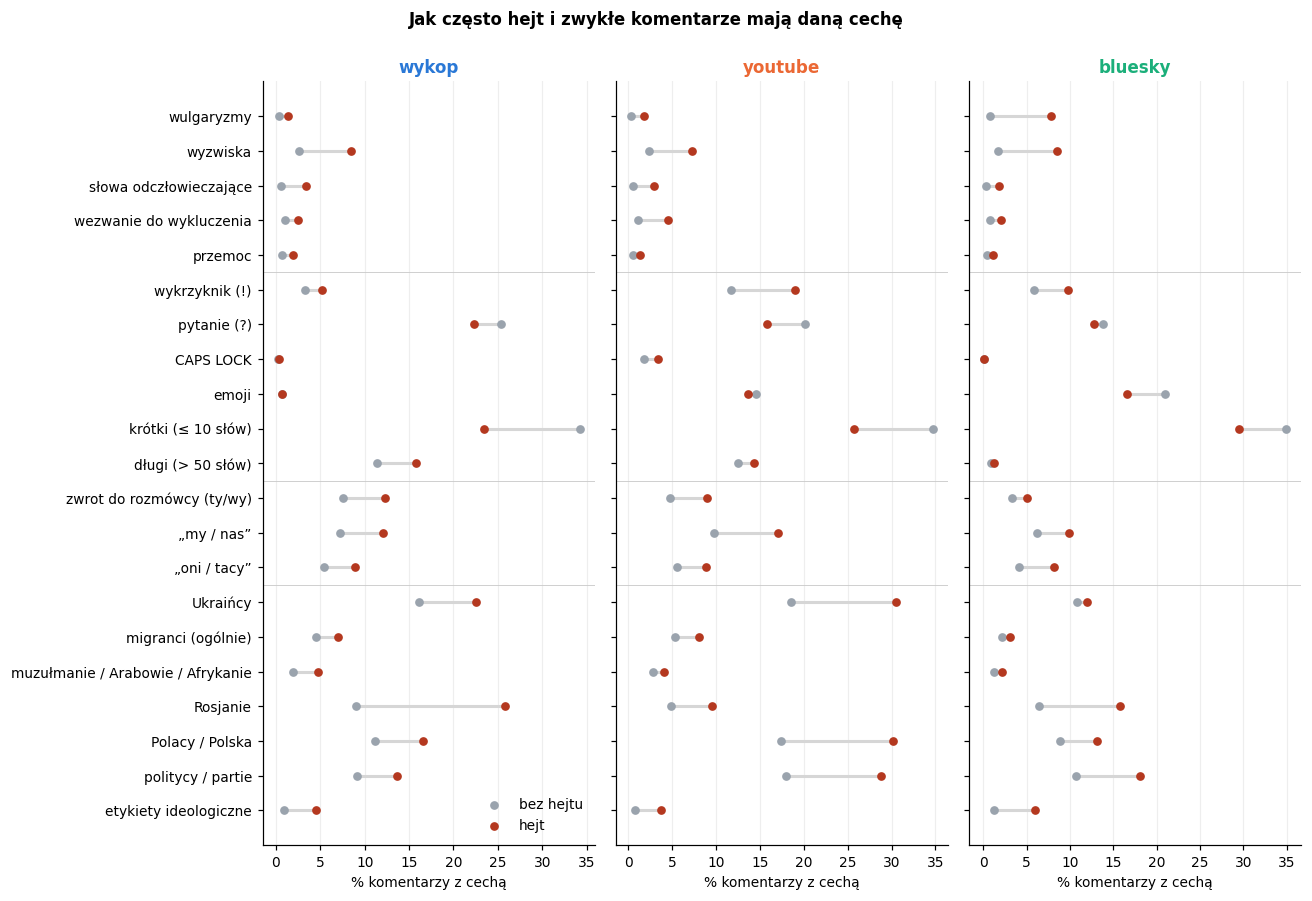

In [5]:
def plot_profile(lang):
    k = 0 if lang == "pl" else 1
    order = [f for g in GROUPS.values() for f in g]
    names = order if lang == "pl" else [EN[f] for f in order]
    fig, axes = plt.subplots(1, len(PL), figsize=(4.0 * len(PL), 0.33 * len(order) + 1.2), sharey=True)
    y = np.arange(len(order))[::-1]
    for ax, p in zip(axes, PL):
        h, n = prof.loc[order, (p, 1)].values, prof.loc[order, (p, 0)].values
        ax.hlines(y, np.minimum(h, n), np.maximum(h, n), color="#d6d6d6", lw=2)
        ax.scatter(n, y, color=NON_C, s=22, label=TXT["non"][k], zorder=3)
        ax.scatter(h, y, color=HATE_C, s=22, label=TXT["hate"][k], zorder=3)
        ax.set_yticks(y, names)
        ax.set_title(p, color=COL[p])
        ax.set_xlabel("% komentarzy z cechą" if lang == "pl" else "% of comments with the feature")
        ax.grid(axis="x", color="#eeeeee")
        cut = len(order)
        for g in list(GROUPS)[:-1]:
            cut -= len(GROUPS[g])
            ax.axhline(cut - 0.5, color="#cccccc", lw=0.6)
    axes[0].legend(loc="lower right", frameon=False)
    fig.suptitle("Jak często hejt i zwykłe komentarze mają daną cechę" if lang == "pl"
                 else "How often hateful and non-hateful comments have each feature", fontweight="bold", y=1.0)
    plt.tight_layout()
    save(fig, "ha_2_cechy" if lang == "pl" else "ha_2_profile", lang)
    return fig


plot_profile("en"); plt.close()
plot_profile("pl"); plt.show()

## 3. Czy hejt jest dłuższy?

Rozkład długości (liczba słów) komentarzy z hejtem i bez hejtu, osobno na każdej platformie. Oś pozioma jest logarytmiczna, bo większość komentarzy jest krótka,
a nieliczne bardzo długie. Pionowe linie to mediany. Pod wykresem: test Manna–Whitneya (czy długości różnią się między grupami)
i wielkość efektu r (rank-biserial: 0 – brak różnicy, ±1 – każdy komentarz jednej grupy dłuższy od każdego z drugiej; dodatnie = hejt dłuższy).

,mediana: hejt,mediana: bez hejtu,średnia: hejt,średnia: bez hejtu,r (rank-biserial),p
platform,,,,,,
wykop,20.0,15.0,31.255,25.619,0.160,0.0
youtube,19.0,15.0,31.256,28.171,0.118,0.0
bluesky,17.0,16.0,21.211,19.986,0.062,0.0


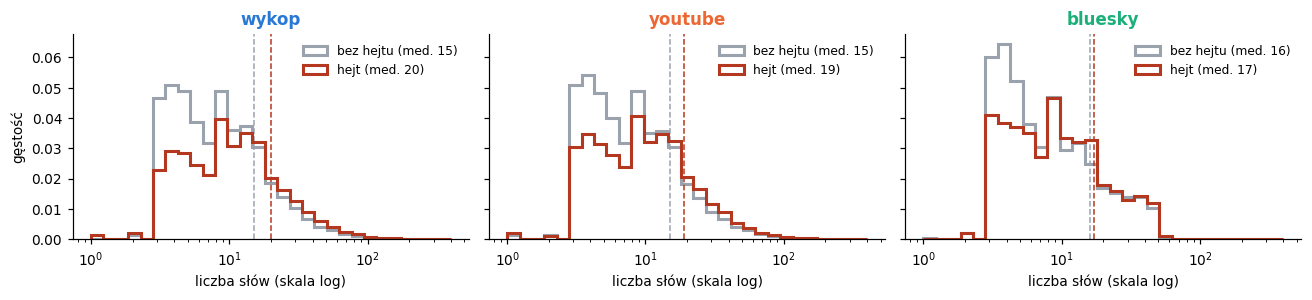

In [6]:
from scipy.stats import mannwhitneyu

rows = []
for p in PL:
    a = df.loc[(df.platform == p) & (df.hate == 1), "n_words"]
    b = df.loc[(df.platform == p) & (df.hate == 0), "n_words"]
    u = mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"platform": p, "mediana: hejt": a.median(), "mediana: bez hejtu": b.median(),
                 "średnia: hejt": a.mean(), "średnia: bez hejtu": b.mean(),
                 "r (rank-biserial)": 2 * u.statistic / (len(a) * len(b)) - 1, "p": u.pvalue})
length = pd.DataFrame(rows).set_index("platform")
display(length.round(3))


def plot_length(lang):
    k = 0 if lang == "pl" else 1
    fig, axes = plt.subplots(1, len(PL), figsize=(4.0 * len(PL), 2.8), sharey=True)
    bins = np.logspace(0, np.log10(400), 30)
    for ax, p in zip(axes, PL):
        for h, c in ((0, NON_C), (1, HATE_C)):
            v = df.loc[(df.platform == p) & (df.hate == h), "n_words"].clip(1, 400)
            ax.hist(v, bins=bins, density=True, histtype="step", lw=2, color=c,
                    label=f"{TXT['hate' if h else 'non'][k]} (med. {v.median():.0f})")
            ax.axvline(v.median(), color=c, ls="--", lw=1)
        ax.set_xscale("log")
        ax.set_title(p, color=COL[p])
        ax.set_xlabel("liczba słów (skala log)" if lang == "pl" else "number of words (log scale)")
        ax.legend(frameon=False, fontsize=8)
    axes[0].set_ylabel("gęstość" if lang == "pl" else "density")
    plt.tight_layout()
    save(fig, "ha_3_dlugosc" if lang == "pl" else "ha_3_length", lang)
    return fig


plot_length("en"); plt.close()
plot_length("pl"); plt.show()

## 4. Które cechy są związane z hejtem, gdy uwzględnimy wszystkie naraz?

Cechy występują razem (np. wulgaryzm i wykrzyknik), a ich częstość zależy od platformy i wydarzenia. Dlatego liczymy jedną regresję logistyczną:
`hate ~ wszystkie cechy + log(liczba słów) + komórka (wydarzenie × platforma)`, z błędami standardowymi klastrowanymi po wątku
(komentarze z jednego wątku nie są niezależne).

- Tylko komentarze ocenione przez sam model (bez słownika obelg), żeby wynik nie odtwarzał słownika.
- **OR** (iloraz szans) mówi, ile razy rosną szanse, że komentarz jest hejtem, gdy ma daną cechę, a pozostałe cechy są takie same.
  OR = 1 – brak związku, OR = 2 – szanse dwa razy większe, OR = 0,5 – dwa razy mniejsze.
- Kreska to 95% przedział ufności. Gdy nie przecina 1, związek jest istotny.
- To związek w danych (co model HerBERT uznaje za hejt), a nie przyczyna.

n = 239,552 komentarzy, 15,779 wątków; hejt: 35.5%


,OR,CI dolny,CI górny,p
cecha,,,,
wulgaryzmy,6.666,5.820,7.634,0.000
słowa odczłowieczające,5.013,4.527,5.551,0.000
etykiety ideologiczne,4.546,4.107,5.031,0.000
wyzwiska,3.315,3.137,3.504,0.000
wezwanie do wykluczenia,2.995,2.745,3.268,0.000
Rosjanie,2.787,2.643,2.938,0.000
przemoc,2.269,2.055,2.506,0.000
zwrot do rozmówcy (ty/wy),1.742,1.661,1.826,0.000
politycy / partie,1.636,1.558,1.719,0.000


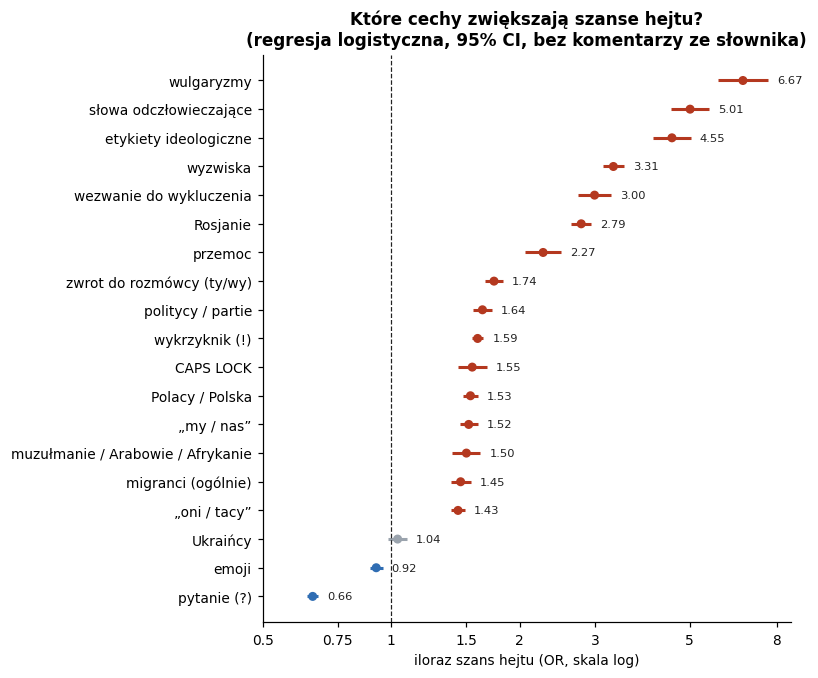

In [7]:
NO_REG = ("krótki (≤ 10 słów)", "długi (> 50 słów)")  # długość wchodzi jako log(liczba słów)
m = df.loc[~df["dict"], ["hate", "n_words", "cell", "thread"] + [f"f_{f}" for f in FEATURES if f not in NO_REG]]
safe = {f: "x" + str(i) for i, f in enumerate(FEATURES)}
X = m[[f"f_{f}" for f in FEATURES if f not in NO_REG]].astype(int)
X.columns = [safe[c[2:]] for c in X.columns]
X["log_words"] = np.log1p(m["n_words"])
X = pd.concat([X, pd.get_dummies(m["cell"], prefix="c", drop_first=True, dtype=int)], axis=1)
X = sm.add_constant(X).astype(np.float64)
res = sm.GLM(m["hate"].to_numpy(dtype=np.float64), X, family=sm.families.Binomial()).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(m["thread"])[0]})
inv = {v: k for k, v in safe.items()}
ci = res.conf_int()
rows = [(inv[k], np.exp(res.params[k]), *np.exp(ci.loc[k]), res.pvalues[k]) for k in res.params.index if k in inv]
rows.append(("log(liczba słów)", np.exp(res.params["log_words"]), *np.exp(ci.loc["log_words"]), res.pvalues["log_words"]))
orr = pd.DataFrame(rows, columns=["cecha", "OR", "CI dolny", "CI górny", "p"]).set_index("cecha")
print(f"n = {len(m):,} komentarzy, {m['thread'].nunique():,} wątków; hejt: {m['hate'].mean():.1%}")
display(orr.sort_values("OR", ascending=False).round(3))
del X, m
gc.collect()


def plot_or(lang):
    o = orr.drop(index="log(liczba słów)").sort_values("OR")
    names = o.index if lang == "pl" else [EN[f] for f in o.index]
    fig, ax = plt.subplots(figsize=(6.2, 0.3 * len(o) + 1))
    y = np.arange(len(o))
    c = [HATE_C if lo > 1 else ("#2f6db3" if hi < 1 else NON_C) for lo, hi in zip(o["CI dolny"], o["CI górny"])]
    ax.hlines(y, o["CI dolny"], o["CI górny"], color=c, lw=2)
    ax.scatter(o["OR"], y, color=c, s=24, zorder=3)
    ax.axvline(1, color=INK, ls="--", lw=0.8)
    ax.set_xscale("log")
    ax.set_xticks([0.5, 0.75, 1, 1.5, 2, 3, 5, 8], ["0.5", "0.75", "1", "1.5", "2", "3", "5", "8"])
    ax.minorticks_off()
    ax.set_yticks(y, names)
    for yi, v in enumerate(o["OR"]):
        ax.text(o["CI górny"].iloc[yi] * 1.05, yi, f"{v:.2f}", va="center", fontsize=7.5, color=INK)
    if lang == "pl":
        ax.set_xlabel("iloraz szans hejtu (OR, skala log)")
        ax.set_title("Które cechy zwiększają szanse hejtu?\n(regresja logistyczna, 95% CI, bez komentarzy ze słownika)")
    else:
        ax.set_xlabel("adjusted odds ratio of hate (log scale)")
        ax.set_title("Which features are associated with hate?\n(logistic regression, 95% CI, model-labelled comments)")
    save(fig, "ha_4_regresja" if lang == "pl" else "ha_4_logit", lang)
    return fig


plot_or("en"); plt.close()
plot_or("pl"); plt.show()

## 5. Czy hejt dostaje więcej polubień i odpowiedzi?

- Na Wykopie „polubienia” to saldo głosów (plusy minus minusy), więc wartości ujemne liczymy jako 0. YouTube nie zapisuje liczby odpowiedzi.
- Model ujemny dwumianowy (polubienia to liczby z długim ogonem: większość komentarzy ma 0–2, nieliczne setki):
  `polubienia ~ hejt + komórka`, błędy klastrowane po wątku.
- Wynik `×` to stosunek średniej liczby polubień (odpowiedzi) hejtu do średniej komentarzy bez hejtu w tej samej komórce:
  ×1,3 – hejt dostaje średnio o 30% więcej, ×0,6 – o 40% mniej. Kreska to 95% przedział ufności; jeśli przecina 1, różnica jest nieistotna.
- Kolumny `% ≥1` – odsetek komentarzy, które dostały choć jedno polubienie (odpowiedź).

n      ×  CI dolny  CI górny    p  % ≥1 (hejt)  \
platform co                                                                
wykop    polubienia   86421  1.272     1.194     1.354  0.0       59.861   
         odpowiedzi   86421  1.328     1.237     1.426  0.0       12.305   
youtube  polubienia  145471  0.645     0.584     0.713  0.0       49.305   
bluesky  polubienia   18704  1.218     1.137     1.305  0.0       73.207   
         odpowiedzi   18704  0.879     0.840     0.918  0.0       49.839   

                     % ≥1 (bez hejtu)  
platform co                            
wykop    polubienia            55.219  
         odpowiedzi             9.797  
youtube  polubienia            55.118  
bluesky  polubienia            67.958  
         odpowiedzi            58.685

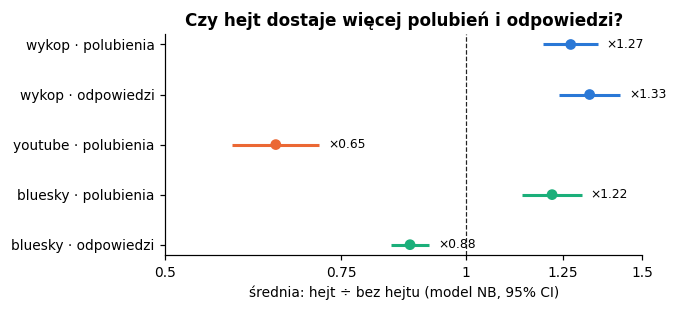

In [8]:
rows = []
for p in PL:
    for y in ("likes", "replies"):
        d = df.loc[(df["platform"] == p) & df[y].notna(), [y, "hate", "cell", "thread"]].copy()
        if len(d) < 500 or d[y].sum() == 0:
            continue
        d[y] = d[y].clip(lower=0)
        f = smf.glm(f"{y} ~ hate + C(cell)", d, family=sm.families.NegativeBinomial(alpha=1.0)).fit(
            cov_type="cluster", cov_kwds={"groups": pd.factorize(d["thread"])[0]})
        rows.append({"platform": p, "co": "polubienia" if y == "likes" else "odpowiedzi", "n": len(d),
                     "×": np.exp(f.params["hate"]), "CI dolny": np.exp(f.conf_int().loc["hate", 0]),
                     "CI górny": np.exp(f.conf_int().loc["hate", 1]), "p": f.pvalues["hate"],
                     "% ≥1 (hejt)": 100 * (d.loc[d.hate == 1, y] > 0).mean(),
                     "% ≥1 (bez hejtu)": 100 * (d.loc[d.hate == 0, y] > 0).mean()})
eng = pd.DataFrame(rows).set_index(["platform", "co"])
display(eng.round(3))


def plot_eng(lang):
    lab = {"polubienia": ("polubienia", "likes"), "odpowiedzi": ("odpowiedzi", "replies")}
    k = 0 if lang == "pl" else 1
    fig, ax = plt.subplots(figsize=(5.6, 2.6))
    yy = np.arange(len(eng))[::-1]
    cols = [COL[p] for p, _ in eng.index]
    ax.hlines(yy, eng["CI dolny"], eng["CI górny"], color=cols, lw=2)
    ax.scatter(eng["×"], yy, color=cols, zorder=3)
    for yi, (v, hi) in zip(yy, zip(eng["×"], eng["CI górny"])):
        ax.text(hi * 1.02, yi, f"×{v:.2f}", va="center", fontsize=8)
    ax.axvline(1, color=INK, ls="--", lw=0.8)
    ax.set_yticks(yy, [f"{p} · {lab[c][k]}" for p, c in eng.index])
    ax.set_xscale("log")
    ax.set_xticks([0.5, 0.75, 1, 1.25, 1.5], ["0.5", "0.75", "1", "1.25", "1.5"])
    ax.minorticks_off()
    if lang == "pl":
        ax.set_xlabel("średnia: hejt ÷ bez hejtu (model NB, 95% CI)")
        ax.set_title("Czy hejt dostaje więcej polubień i odpowiedzi?")
    else:
        ax.set_xlabel("mean count: hate ÷ non-hate (negative binomial, 95% CI)")
        ax.set_title("Does hate receive more likes and replies?")
    save(fig, "ha_5_reakcje" if lang == "pl" else "ha_5_engagement", lang)
    return fig


plot_eng("en"); plt.close()
plot_eng("pl"); plt.show()

## 6. Czy hejterzy piszą wyłącznie hejt?

Tylko Wykop i Bluesky (YouTube nie ma identyfikatorów autorów). Na Bluesky autor jest liczony osobno w każdym wydarzeniu.

- **% autorów z ≥1 hejtem** – jaka część autorów napisała choć jeden komentarz z hejtem,
- **top 1% / top 10% hejterów** – jaką część całego hejtu napisało 1% / 10% najaktywniejszych hejterów,
- **Gini** – jak nierówno rozłożone jest pisanie (0 – wszyscy piszą tyle samo, 1 – jedna osoba pisze wszystko),
- **wykres** – dla autorów z co najmniej 5 komentarzami: jaki odsetek ich komentarzy to hejt. Słupek przy 0% to osoby, które nigdy nie hejtują,
  słupek przy 100% – osoby, które piszą wyłącznie hejt.

,autorzy,% autorów z ≥1 hejtem,top 1% hejterów: % hejtu,top 10% hejterów: % hejtu,Gini (hejt),Gini (wszystkie komentarze),aktywni (≥5 kom.),mediana % hejtu u aktywnych,% aktywnych bez hejtu,% aktywnych z >80% hejtu
platform,,,,,,,,,,
wykop,12374,58.1,12.3,46.3,0.6,0.7,4039,33.3,9.0,2.5
bluesky,3248,45.3,13.5,41.6,0.5,0.6,984,16.7,23.0,0.7


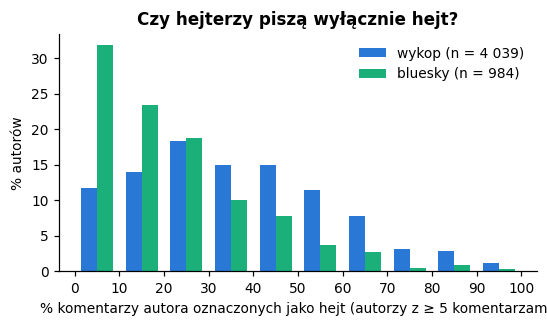

In [9]:
def gini(x):
    x = np.sort(np.asarray(x, float))
    n = len(x)
    return 2 * (np.arange(1, n + 1) * x).sum() / (n * x.sum()) - (n + 1) / n


def top_share(x, q):
    x = np.sort(np.asarray(x, float))[::-1]
    return 100 * x[:max(1, int(np.ceil(q * len(x))))].sum() / x.sum()


rows, mix = [], {}
for p in PL:
    a = df[(df["platform"] == p) & df["author"].notna()].groupby("author")["hate"].agg(["size", "sum"])
    if len(a) < 100:
        continue
    haters = a[a["sum"] > 0]
    act = a[a["size"] >= 5]
    share = 100 * act["sum"] / act["size"]
    mix[p] = share
    rows.append({"platform": p, "autorzy": len(a), "% autorów z ≥1 hejtem": 100 * len(haters) / len(a),
                 "top 1% hejterów: % hejtu": top_share(haters["sum"], .01),
                 "top 10% hejterów: % hejtu": top_share(haters["sum"], .10),
                 "Gini (hejt)": gini(haters["sum"]), "Gini (wszystkie komentarze)": gini(a["size"]),
                 "aktywni (≥5 kom.)": len(act), "mediana % hejtu u aktywnych": share.median(),
                 "% aktywnych bez hejtu": 100 * (share == 0).mean(), "% aktywnych z >80% hejtu": 100 * (share > 80).mean()})
auth = pd.DataFrame(rows).set_index("platform")
display(auth.round(1))


def plot_auth(lang):
    fig, ax = plt.subplots(figsize=(5.6, 2.8))
    bins = np.linspace(0, 100, 11)
    w = 3.6
    for k, (p, v) in enumerate(mix.items()):
        h, _ = np.histogram(v, bins=bins)
        ax.bar(bins[:-1] + 5 + (k - 0.5) * w, 100 * h / h.sum(), width=w, color=COL[p],
               label=f"{p} (n = {len(v):,})".replace(",", " "))
    ax.set_xticks(bins)
    if lang == "pl":
        ax.set_xlabel("% komentarzy autora oznaczonych jako hejt (autorzy z ≥ 5 komentarzami)")
        ax.set_ylabel("% autorów")
        ax.set_title("Czy hejterzy piszą wyłącznie hejt?")
    else:
        ax.set_xlabel("% of an author's comments labelled hate (authors with ≥ 5 comments)")
        ax.set_ylabel("% of authors")
        ax.set_title("Do haters write only hate?")
    ax.legend(frameon=False)
    save(fig, "ha_6_autorzy" if lang == "pl" else "ha_6_authors", lang)
    return fig


plot_auth("en"); plt.close()
plot_auth("pl"); plt.show()

## 7. Podsumowanie

In [10]:
summary = pd.DataFrame({
    "hejt %": lvl["hejt %"].round(1),
    "mediana słów (hejt / bez)": [f"{length.loc[p, 'mediana: hejt']:.0f} / {length.loc[p, 'mediana: bez hejtu']:.0f}" for p in PL],
    "wulgaryzmy % (hejt / bez)": [f"{prof.loc['wulgaryzmy', (p, 1)]:.1f} / {prof.loc['wulgaryzmy', (p, 0)]:.1f}" for p in PL],
    "wykrzyknik % (hejt / bez)": [f"{prof.loc['wykrzyknik (!)', (p, 1)]:.1f} / {prof.loc['wykrzyknik (!)', (p, 0)]:.1f}" for p in PL],
    "polubienia ×": [f"{eng.loc[(p, 'polubienia'), '×']:.2f}" if (p, "polubienia") in eng.index else "–" for p in PL],
    "odpowiedzi ×": [f"{eng.loc[(p, 'odpowiedzi'), '×']:.2f}" if (p, "odpowiedzi") in eng.index else "–" for p in PL],
    "% autorów z ≥1 hejtem": [f"{auth.loc[p, '% autorów z ≥1 hejtem']:.0f}" if p in auth.index else "–" for p in PL],
}, index=PL)
display(summary)
summary.to_csv(OUT / "ha_podsumowanie.csv")
orr.to_csv(OUT / "ha_regresja_or.csv")
tab.to_csv(OUT / "ha_cechy.csv")

,hejt %,mediana słów (hejt / bez),wulgaryzmy % (hejt / bez),wykrzyknik % (hejt / bez),polubienia ×,odpowiedzi ×,% autorów z ≥1 hejtem
wykop,33.7,20 / 15,1.4 / 0.3,5.2 / 3.3,1.27,1.33,58
youtube,43.5,19 / 15,1.7 / 0.3,19.0 / 11.7,0.65,–,–
bluesky,20.0,17 / 16,7.8 / 0.7,9.8 / 5.9,1.22,0.88,45


**Wnioski** (11 wydarzeń, okno −7…+14, komentarze w filtrze tematycznym; etykiety HerBERT-a)

1. **Hejt rozpoznajemy po języku, nie po temacie.** Gdy uwzględnimy wszystkie cechy naraz, najsilniej z hejtem wiążą się
   wulgaryzmy (OR ≈ 6,7), słowa odczłowieczające (≈ 5,0), etykiety ideologiczne typu „lewak”, „katol”, „faszysta” (≈ 4,5),
   wyzwiska (≈ 3,3) i wezwania do wykluczenia („won”, „precz”, „deportować”; ≈ 3,0). Sama wzmianka o Ukraińcach – gdy pominiemy
   komentarze ze słownika obelg – nie zwiększa szans hejtu (OR 1,04, nieistotne): liczy się sposób mówienia, a nie to, o kim się mówi.
2. **Hejt jest bardziej emocjonalny i rzadziej pyta.** Hejt częściej ma wykrzyknik (OR 1,6) i CAPS LOCK (1,5), a rzadziej znak zapytania (0,66).
3. **Hejt jest trochę dłuższy.** Mediana 20 vs 15 słów na Wykopie, 19 vs 15 na YouTube, 17 vs 16 na Bluesky (efekt mały, r = 0,06–0,16).
   Po uwzględnieniu pozostałych cech sama długość szans nie zwiększa (OR 0,86 na log-długość): dłuższe komentarze po prostu częściej
   zawierają wyzwisko albo wzmiankę o grupie.
4. **„My – oni” i zwrot do rozmówcy.** Hejt częściej zawiera „my/nas” (OR 1,5), „oni/tacy” (1,4) i „Polak/Polska” (1,5), a także
   zwrot „ty/wy” (1,7) – część hejtu jest wymierzona w uczestnika dyskusji, a nie w grupę.
5. **Hejt w wątkach o migracji nie dotyczy tylko migrantów.** Wzmianki o Rosjanach (OR 2,8) i o politykach / partiach (1,6) są z hejtem
   związane silniej niż wzmianki o migrantach (1,5) czy Ukraińcach (1,0). Hejt ogólny to w dużej części hejt antyrosyjski i polityczny,
   dlatego hejt wobec migrantów wymaga osobnej etykiety (LLM).
6. **Reakcje zależą od platformy.** Na Wykopie hejt dostaje więcej polubień (×1,27) i odpowiedzi (×1,33), na Bluesky więcej polubień (×1,22),
   ale mniej odpowiedzi (×0,88), a na YouTube wyraźnie mniej polubień (×0,65).
7. **Hejterzy nie piszą wyłącznie hejtu.** Choć jeden hejt napisało 58% autorów na Wykopie i 45% na Bluesky. Top 1% hejterów pisze
   ok. 12–14% hejtu. Typowy aktywny autor miesza hejt ze zwykłymi komentarzami (mediana 33% hejtu na Wykopie, 17% na Bluesky);
   autorów piszących prawie wyłącznie hejt (> 80% komentarzy) jest 2,5% na Wykopie i 0,7% na Bluesky.

**Ograniczenia.** Etykiety pochodzą z modelu (HerBERT, F1 = 0,78 na gold standardzie), więc wyniki opisują to, co model uznaje za hejt.
Cechy to proste reguły słownikowe (listy w sekcji 2). To zależności w danych, a nie przyczyny.